# 6. Laplace's method

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 5

Integrals of the form

$$ I(\lambda) = \int_a^b g(t)\,e^{\lambda f(t)}\,\mathrm dt , \qquad \lambda \to \infty , $$

are everywhere in the physical sciences. In statistical mechanics $\lambda$ is
$1/k_BT$ and the integral is a partition function; in probability it is the number
of trials and the integral a likelihood; in chemical kinetics it is a barrier height
over $k_BT$ (Chapter 10). For large $\lambda$ the exponential magnifies the largest
value of $f$ beyond all others, and the integral is decided in a small
neighbourhood of the maximum. Laplace (1774), working on inverse probability,
turned this observation into a method: expand $f$ to second order about its
maximum and integrate the resulting Gaussian.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 40

## 6.1 The leading term

Let $f$ have a single maximum at an interior point $t_0$, with $f'(t_0) = 0$ and
$f''(t_0) = -a < 0$. Near $t_0$,

$$ \lambda f(t) \approx \lambda f(t_0) - \tfrac12\lambda a\,(t - t_0)^2 , $$

a Gaussian of width $(\lambda a)^{-1/2}$, which shrinks as $\lambda$ grows. Over
that width $g$ hardly changes and can be replaced by $g(t_0)$; the limits can be
moved to $\pm\infty$ at an exponentially small cost. The Gaussian integral gives

$$ I(\lambda) \sim g(t_0)\,e^{\lambda f(t_0)}\sqrt{\frac{2\pi}{\lambda a}} . $$

Two remarks. The exponent must be expanded to second order exactly: a relative
error $\delta$ in the exponent is an error $\lambda\delta$ in the logarithm of the
result (Section 3.1). And the result depends on only three numbers: the height
$f(t_0)$, the curvature $a$, and the prefactor $g(t_0)$.

## 6.2 The first correction

The leading term has a relative error of order $1/\lambda$. To find the correction,
put $t = t_0 + s/\sqrt\lambda$ and expand both functions further:

$$ \lambda f = \lambda f_0 - \tfrac12 a s^2 + \frac{f_3 s^3}{6\sqrt\lambda} + \frac{f_4 s^4}{24\lambda} + \dots , \qquad
   g = g_0 + \frac{g_1 s}{\sqrt\lambda} + \frac{g_2 s^2}{2\lambda} + \dots , $$

where $f_k$ and $g_k$ are the derivatives at $t_0$. Expanding the exponential of the
small terms, keeping everything of order $1/\lambda$ (including the square of the
cubic term), and integrating against the Gaussian with its moments
$\langle s^2\rangle = 1/a$, $\langle s^4\rangle = 3/a^2$, $\langle s^6\rangle = 15/a^3$,
the odd terms vanish and

$$ I(\lambda) \sim e^{\lambda f_0}\sqrt{\frac{2\pi}{\lambda a}}
   \left[g_0 + \frac1\lambda\left(\frac{g_2}{2a} + \frac{g_1 f_3}{2a^2}
   + \frac{g_0 f_4}{8a^2} + \frac{5 g_0 f_3^2}{24a^3}\right) + O(\lambda^{-2})\right] . $$

The function `am.laplace_method` evaluates this formula. Note the term in $f_3^2$:
an asymmetric peak contributes at order $1/\lambda$ through the *square* of its
skewness, because the first power averages to zero.

## 6.3 Stirling's formula

The most famous application is the factorial. With $t = \lambda u$,

$$ \Gamma(\lambda + 1) = \int_0^\infty t^\lambda e^{-t}\,\mathrm dt
   = \lambda^{\lambda+1}\int_0^\infty e^{\lambda(\ln u - u)}\,\mathrm du . $$

Here $f = \ln u - u$ has its maximum at $u_0 = 1$ with $f_0 = -1$, $f_2 = -1$,
$f_3 = 2$, $f_4 = -6$, and $g = 1$. The leading term is Stirling's formula,
$\Gamma(\lambda + 1) \sim \sqrt{2\pi\lambda}\,\lambda^\lambda e^{-\lambda}$, and the
correction is $\frac1\lambda\left(-\frac68 + \frac{5\cdot 4}{24}\right) = \frac{1}{12\lambda}$,
the first term of the Stirling series (Chapter 9).

In [2]:
lams = np.logspace(0.5, 3, 25)
logG_exact = np.array([float(mp.loggamma(L + 1)) for L in lams])
stirl = {}
for k, corr in enumerate((False, True)):
    # f0 = -1 is added as -L by hand: exp(-L) would underflow for L ~ 1000
    approx = np.array([math.log(am.laplace_method(L, 0.0, -1.0, 1.0, f3=2.0, f4=-6.0, correction=corr))
                       - L + (L + 1) * math.log(L) for L in lams])
    stirl[k + 1] = np.abs(np.expm1(approx - logG_exact))
stirl[3] = np.abs(np.expm1(np.log1p(1 / (12 * lams) + 1 / (288 * lams**2))
                           + 0.5 * np.log(2 * np.pi * lams) + lams * np.log(lams) - lams - logG_exact))
for k, label in ((1, "leading term"), (2, "with 1/(12 lam)"), (3, "with 1/(288 lam^2) as well")):
    # for the third, fit below lam = 100: beyond, errors of 1e-12 are lost in logarithms of size ~ 7000
    s, p = am.loglog_slope(lams, stirl[k], fit_range=(50, 1000) if k < 3 else (10, 100))
    print(f"Stirling, {label:28s}: relative error ~ {p:.4g} lam^{s:.3f}")
print(f"(predicted prefactors: 1/12 = {1 / 12:.4f}, 1/288 = {1 / 288:.4g}, 139/51840 = {139 / 51840:.4g})")

Stirling, leading term                : relative error ~ 0.08321 lam^-1.000
Stirling, with 1/(12 lam)             : relative error ~ 0.003369 lam^-1.995
Stirling, with 1/(288 lam^2) as well  : relative error ~ 0.002671 lam^-2.999
(predicted prefactors: 1/12 = 0.0833, 1/288 = 0.003472, 139/51840 = 0.002681)


The leading term errs by $1/(12\lambda)$; with the correction, by $1/(288\lambda^2)$,
the next term of the series; and with that term as well, by about
$139/(51840\lambda^3)$, as the prefactors confirm. Even at $\lambda = 1$ the
leading term is within 8 % of $1! = 1$: Laplace's method is often useful long
before $\lambda$ is large.

## 6.4 Two more examples

**The modified Bessel function.** In problems with cylindrical symmetry, and in the
statistics of directions (the von Mises distribution), one meets

$$ I_0(\lambda) = \frac{1}{2\pi}\int_{-\pi}^{\pi} e^{\lambda\cos\theta}\,\mathrm d\theta . $$

The maximum is at $\theta = 0$, with $f_0 = 1$, $f_2 = -1$, $f_3 = 0$, $f_4 = 1$ and
$g = 1/2\pi$, so $I_0(\lambda) \sim \frac{e^\lambda}{\sqrt{2\pi\lambda}}\left(1 + \frac{1}{8\lambda}\right)$.

**Laplace's own problem.** In inverse probability, after $k$ successes in $n$ trials
with an unknown success probability $t$, Laplace needed integrals of the
likelihood $t^k(1-t)^{n-k}$. With $n = \lambda$ and $k = \lambda p$,

$$ B(\lambda) = \int_0^1 t^{\lambda p}(1-t)^{\lambda q}\,\mathrm dt , \qquad q = 1 - p , $$

is a Beta function, known exactly. The exponent $f = p\ln t + q\ln(1-t)$ has its
maximum at $t_0 = p$, the observed frequency, with curvature $a = 1/(pq)$: the
Gaussian that Laplace's method substitutes for the likelihood has variance
$pq/\lambda$. This is the large-sample approximation behind the usual error bar
$\sqrt{p(1-p)/n}$ of a measured proportion. The higher derivatives are
$f_3 = 2/p^2 - 2/q^2$ and $f_4 = -6/p^3 - 6/q^3$.

In [3]:
lams2 = np.logspace(1, 4, 25)
i0_err = {}
for k, corr in enumerate((False, True)):
    approx = np.array([am.laplace_method(L, 0.0, -1.0, 1 / (2 * np.pi), f4=1.0, correction=corr) for L in lams2])   # times e^-L
    exact = np.array([float(mp.besseli(0, L) * mp.exp(-L)) for L in lams2])
    i0_err[k + 1] = np.abs(approx / exact - 1)

p_succ = 0.2
q_fail = 1 - p_succ
f3b, f4b = 2 / p_succ**2 - 2 / q_fail**2, -6 / p_succ**3 - 6 / q_fail**3
f0b = p_succ * math.log(p_succ) + q_fail * math.log(q_fail)
beta_err = {}
for k, corr in enumerate((False, True)):
    approx = np.array([am.laplace_method(L, 0.0, -1 / (p_succ * q_fail), 1.0, f3=f3b, f4=f4b, correction=corr) for L in lams2])
    # the factor exp(lam f0) is compared on a log scale to avoid underflow
    exact_scaled = np.array([float(mp.beta(L * p_succ + 1, L * q_fail + 1) * mp.exp(-L * f0b)) for L in lams2])
    beta_err[k + 1] = np.abs(approx / exact_scaled - 1)
for name, err in (("I0", i0_err), ("Beta, p = 0.2", beta_err)):
    s1, p1 = am.loglog_slope(lams2, err[1], fit_range=(1e3, 1e4))
    s2, p2 = am.loglog_slope(lams2, err[2], fit_range=(1e3, 1e4))
    print(f"{name:14s}: leading term error ~ {p1:.3g} lam^{s1:.3f};  corrected ~ {p2:.3g} lam^{s2:.3f}")
print(f"(I0: predicted 1/8 = 0.125 and 9/128 = {9 / 128:.4f})")

I0            : leading term error ~ 0.125 lam^-1.000;  corrected ~ 0.0705 lam^-2.000
Beta, p = 0.2 : leading term error ~ 0.561 lam^-1.000;  corrected ~ 0.656 lam^-2.000
(I0: predicted 1/8 = 0.125 and 9/128 = 0.0703)


Both examples follow the predicted pattern: the leading term has a relative error
of order $1/\lambda$, the corrected one of order $1/\lambda^2$. For the Beta
integral with $p = 0.2$ the leading error is several times larger than for $I_0$,
because the likelihood is skewed: the $f_3^2$ term is large when $p$ is far from
$1/2$. The same skewness is why a symmetric error bar on a small measured
proportion is inaccurate in a small sample.

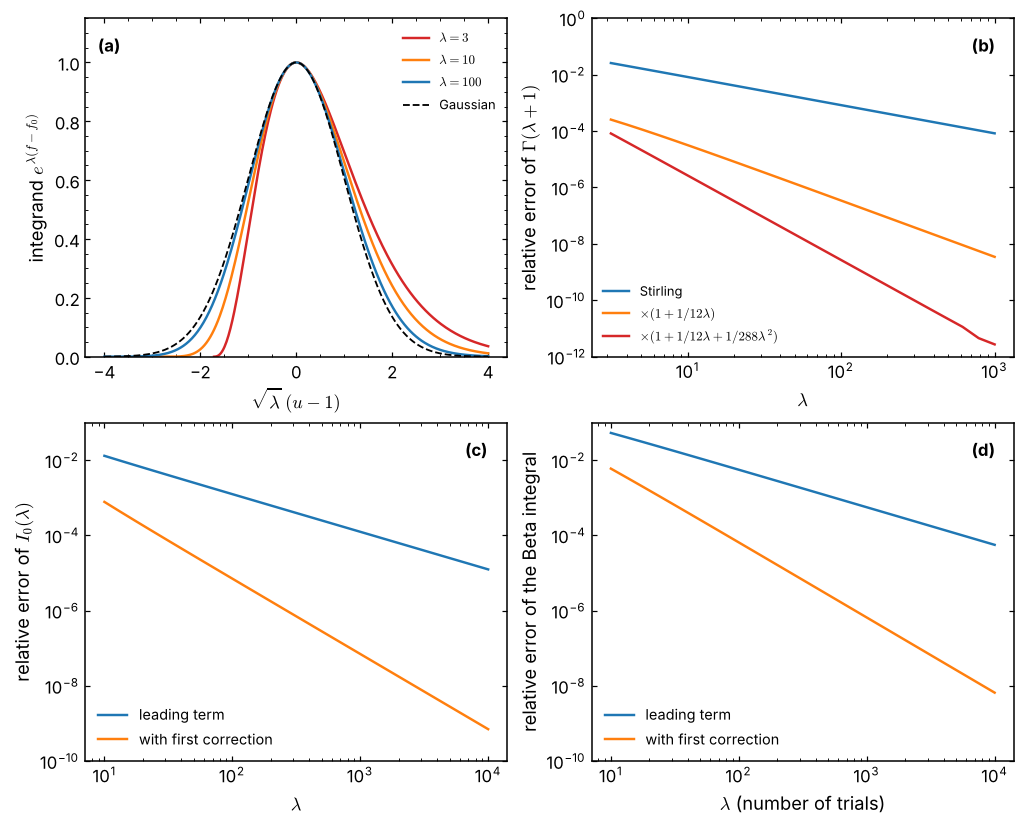

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
for L, c in ((3, "C3"), (10, "C1"), (100, "C0")):
    s = np.linspace(-4, 4, 400)                      # scaled variable s = sqrt(lam) (u - 1)
    u = 1 + s / np.sqrt(L)
    ok = u > 0
    ax.plot(s[ok], np.exp(L * (np.log(u[ok]) - u[ok] + 1)), color=c, label=rf"$\lambda = {L}$")
ax.plot(s, np.exp(-s**2 / 2), "k--", lw=1.2, label="Gaussian")
ax.set_xlabel(r"$\sqrt{\lambda}\,(u - 1)$"); ax.set_ylabel(r"integrand $e^{\lambda(f - f_0)}$")
ax.set_ylim(0, 1.15); ax.legend(loc="upper right", fontsize=8.5); am.panel_label(ax, "(a)")

ax = axes[0, 1]
for k, c, lab in ((1, "C0", "Stirling"), (2, "C1", r"$\times(1 + 1/12\lambda)$"), (3, "C3", r"$\times(1 + 1/12\lambda + 1/288\lambda^2)$")):
    ax.loglog(lams, stirl[k], color=c, label=lab)
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"relative error of $\Gamma(\lambda + 1)$")
ax.set_ylim(1e-12, 1); ax.legend(loc="lower left", fontsize=8.5); am.panel_label(ax, "(b)", x=0.9)

ax = axes[1, 0]
ax.loglog(lams2, i0_err[1], "C0", label="leading term")
ax.loglog(lams2, i0_err[2], "C1", label="with first correction")
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"relative error of $I_0(\lambda)$")
ax.set_ylim(1e-10, 1e-1); ax.legend(loc="lower left"); am.panel_label(ax, "(c)", x=0.9)

ax = axes[1, 1]
ax.loglog(lams2, beta_err[1], "C0", label="leading term")
ax.loglog(lams2, beta_err[2], "C1", label="with first correction")
ax.set_xlabel(r"$\lambda$ (number of trials)"); ax.set_ylabel(r"relative error of the Beta integral")
ax.set_ylim(1e-10, 1e-1); ax.legend(loc="lower left"); am.panel_label(ax, "(d)", x=0.9)
plt.show()

**(a)** The integrand of $\Gamma(\lambda + 1)$ in the scaled variable
$\sqrt\lambda(u - 1)$: as $\lambda$ grows it approaches the Gaussian of Laplace's
method; for small $\lambda$ it is visibly skewed. **(b)** Relative error of Stirling's
formula and its corrections. **(c)** Relative error of Laplace's method for
$I_0(\lambda)$. **(d)** The same for the Beta integral with $p = 0.2$.

## Summary

* Laplace's method: an integral of $e^{\lambda f}$ is dominated by the maximum of
  $f$; expanding the exponent to second order gives
  $g_0 e^{\lambda f_0}\sqrt{2\pi/\lambda a}$.
* The exponent must be expanded to second order; the prefactor to zeroth.
* The first correction is of relative order $1/\lambda$ and depends on the third
  and fourth derivatives of $f$ and the first two of $g$; skewness enters squared.
* Stirling's formula, the large-$\lambda$ form of Bessel functions and the
  large-sample Gaussian approximation of a likelihood are all Laplace's method.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* N. Bleistein and R. A. Handelsman, *Asymptotic Expansions of Integrals* (Holt,
  Rinehart and Winston, 1975; Dover, 1986).
* N. G. de Bruijn, *Asymptotic Methods in Analysis*, 3rd ed. (North-Holland, 1970;
  Dover, 1981).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* M. H. Holmes, *Introduction to Perturbation Methods*, 2nd ed. (Springer, 2013).
* P. S. Laplace, "Mémoire sur la probabilité des causes par les événements",
  *Mém. Math. Phys. Acad. R. Sci. Paris (Savants étrangers)* **6**, 621 (1774).
* F. W. J. Olver, *Asymptotics and Special Functions* (Academic Press, 1974;
  A K Peters, 1997).

## Exercises

1. Derive the first-correction formula of Section 6.2, including the
   $5f_3^2/24a^3$ term.
2. Use Laplace's method to find the large-$\lambda$ behaviour of
   $\int_0^\infty e^{-\lambda(t + 1/t)}\,\mathrm dt$ (a modified Bessel function $K_1$),
   and check it with `mpmath.besselk`.
3. If the maximum of $f$ lies at an endpoint $a$ with $f'(a) = 0$, show that the
   leading term is half the interior result. What if $f'(a) \neq 0$?
4. For the Beta integral, plot the leading relative error against $p$ at fixed
   $\lambda$ and explain its growth as $p \to 0$.

---

**Previous:** [5. Integration by parts and Watson's lemma](05_integration_by_parts_and_watsons_lemma.ipynb) &nbsp;·&nbsp; **Next:** [7. Stationary phase](07_stationary_phase.ipynb)